In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Pandas version:", pd.__version__)
print("Matplotlib version:", plt.matplotlib.__version__)
print("Seaborn version:", sns.__version__)

print("All tools are ready!")



Pandas version: 2.2.3
Matplotlib version: 3.10.0
Seaborn version: 0.13.2
All tools are ready!


In [ ]:
import seaborn as sns

df = sns.load_dataset("diamonds")

print(df.head())
print("Dataset shape:", df.shape)

   carat      cut color clarity  depth  table  price     x     y     z
0   0.23    Ideal     E     SI2   61.5   55.0    326  3.95  3.98  2.43
1   0.21  Premium     E     SI1   59.8   61.0    326  3.89  3.84  2.31
2   0.23     Good     E     VS1   56.9   65.0    327  4.05  4.07  2.31
3   0.29  Premium     I     VS2   62.4   58.0    334  4.20  4.23  2.63
4   0.31     Good     J     SI2   63.3   58.0    335  4.34  4.35  2.75
Dataset shape: (53940, 10)


Diamond Prices Data Analysis Project

Dataset loaded successfully!

First 5 rows:
   carat      cut color clarity  depth  table  price     x     y     z
0   0.23    Ideal     E     SI2   61.5   55.0    326  3.95  3.98  2.43
1   0.21  Premium     E     SI1   59.8   61.0    326  3.89  3.84  2.31
2   0.23     Good     E     VS1   56.9   65.0    327  4.05  4.07  2.31
3   0.29  Premium     I     VS2   62.4   58.0    334  4.20  4.23  2.63
4   0.31     Good     J     SI2   63.3   58.0    335  4.34  4.35  2.75

Dataset shape (rows, columns):
(53940, 10)

Column names:
['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'price', 'x', 'y', 'z']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null

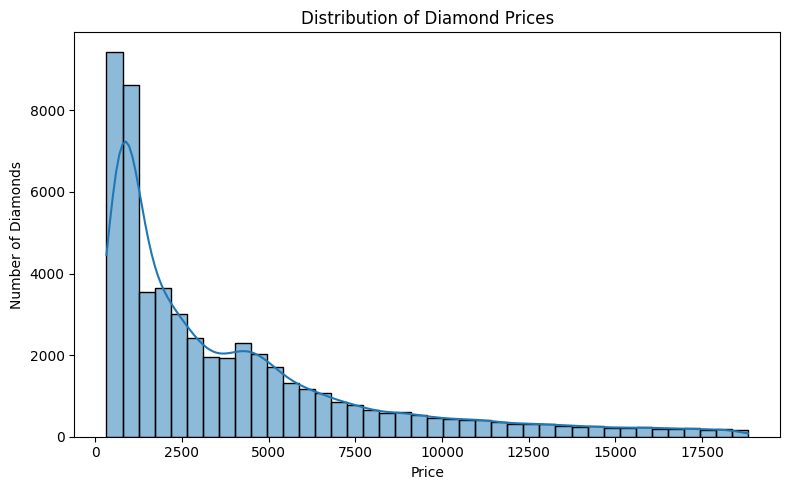

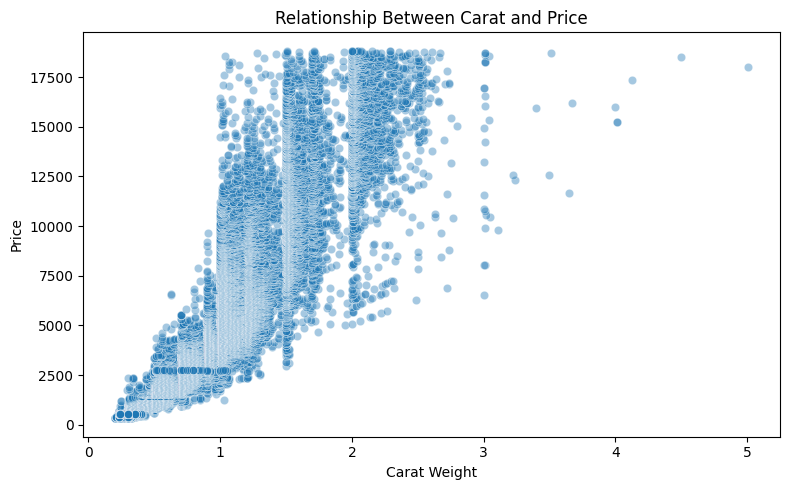

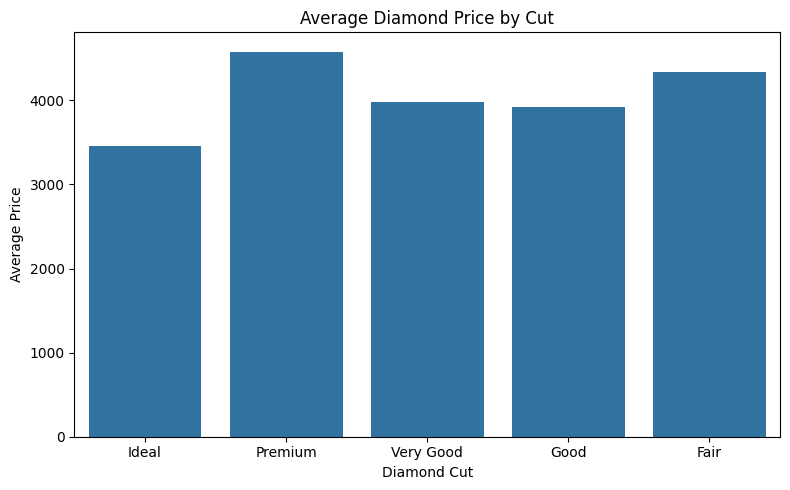

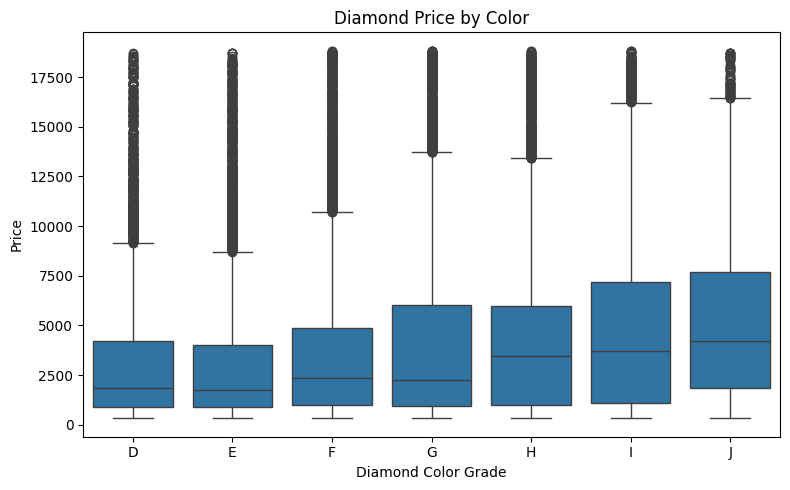

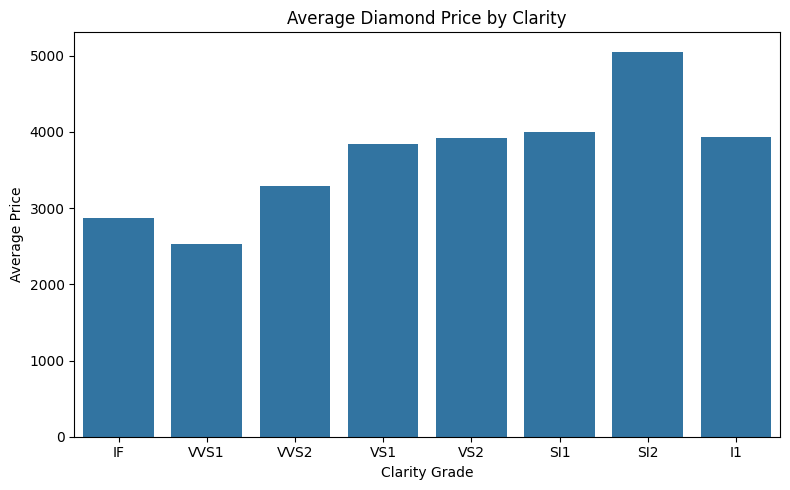

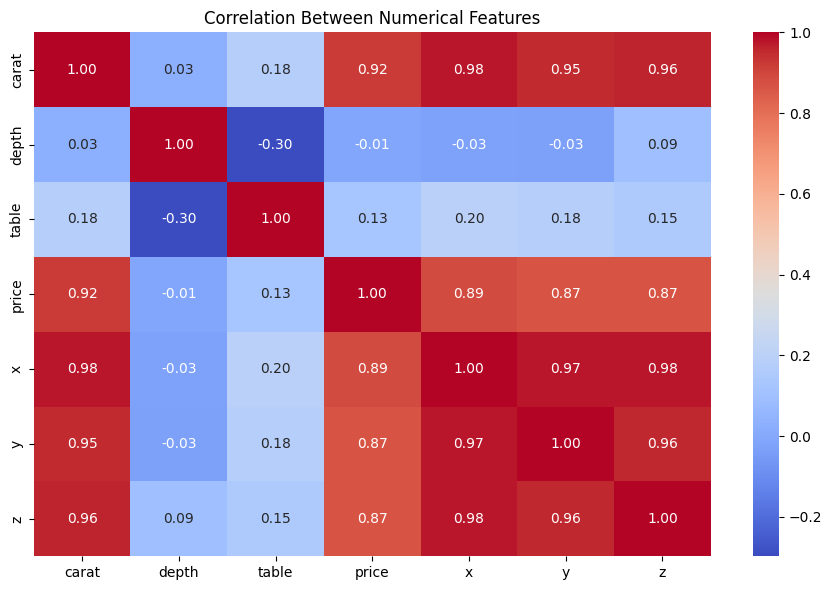


Correlation with diamond price:
carat    0.922
x        0.887
z        0.868
y        0.868
table    0.127
depth   -0.011
Name: price, dtype: float64

Feature most positively correlated with price:
carat
Correlation value: 0.922

Cleaned dataset saved as cleaned_diamonds.csv

PROJECT CONCLUSIONS
1. The cleaned dataset contains 53775 diamond records.
2. The average diamond price is 3931.22.
3. The average carat weight is 0.80.
4. Carat and price correlation is 0.922.
5. The cut category with the highest average price is Premium.
6. The clarity category with the highest average price is SI2.
7. Charts help us understand price distributions and relationships.

Project completed successfully!


In [ ]:
# ============================================================
# PROJECT: DIAMOND PRICES DATA ANALYSIS
# Language: Python
# Libraries: Pandas, Matplotlib, Seaborn
# ============================================================

# STEP 1: Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Diamond Prices Data Analysis Project")
print("=" * 45)

# STEP 2: Load the dataset
# Seaborn's diamonds dataset contains diamond attributes and prices.
try:
    df = sns.load_dataset("diamonds")
except Exception:
    print("Dataset download failed.")
    print("Please upload a diamonds.csv file.")
    from google.colab import files
    uploaded = files.upload()
    df = pd.read_csv(next(iter(uploaded)))

print("\nDataset loaded successfully!")

# STEP 3: Explore the dataset
print("\nFirst 5 rows:")
print(df.head())

print("\nDataset shape (rows, columns):")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
print(df.describe(include="all"))

# STEP 4: Clean the dataset
print("\nMissing values before cleaning:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Remove rows with missing values
df = df.dropna().copy()

# Remove records with invalid or non-positive measurements
df = df[
    (df["carat"] > 0) &
    (df["depth"] > 0) &
    (df["price"] > 0) &
    (df["x"] > 0) &
    (df["y"] > 0) &
    (df["z"] > 0)
].copy()

print("\nDataset cleaned successfully!")
print("Rows after cleaning:", len(df))
print("Missing values after cleaning:", df.isnull().sum().sum())

# STEP 5: Basic data analysis
print("\nAverage diamond price:", round(df["price"].mean(), 2))
print("Minimum diamond price:", df["price"].min())
print("Maximum diamond price:", df["price"].max())
print("Average carat:", round(df["carat"].mean(), 2))

print("\nAverage price by cut:")
print(df.groupby("cut", observed=True)["price"].mean().round(2))

print("\nAverage price by color:")
print(df.groupby("color", observed=True)["price"].mean().round(2))

print("\nAverage price by clarity:")
print(df.groupby("clarity", observed=True)["price"].mean().round(2))

# STEP 6: Chart 1 - Distribution of diamond prices
plt.figure(figsize=(8, 5))
sns.histplot(df["price"], bins=40, kde=True)
plt.title("Distribution of Diamond Prices")
plt.xlabel("Price")
plt.ylabel("Number of Diamonds")
plt.tight_layout()
plt.show()

# STEP 7: Chart 2 - Carat versus price
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="carat",
    y="price",
    alpha=0.4
)
plt.title("Relationship Between Carat and Price")
plt.xlabel("Carat Weight")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

# STEP 8: Chart 3 - Average price by cut
plt.figure(figsize=(8, 5))
sns.barplot(
    data=df,
    x="cut",
    y="price",
    estimator="mean",
    errorbar=None
)
plt.title("Average Diamond Price by Cut")
plt.xlabel("Diamond Cut")
plt.ylabel("Average Price")
plt.tight_layout()
plt.show()

# STEP 9: Chart 4 - Price by color
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="color", y="price")
plt.title("Diamond Price by Color")
plt.xlabel("Diamond Color Grade")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

# STEP 10: Chart 5 - Price by clarity
plt.figure(figsize=(8, 5))
sns.barplot(
    data=df,
    x="clarity",
    y="price",
    estimator="mean",
    errorbar=None
)
plt.title("Average Diamond Price by Clarity")
plt.xlabel("Clarity Grade")
plt.ylabel("Average Price")
plt.tight_layout()
plt.show()

# STEP 11: Chart 6 - Correlation heatmap
numeric_df = df.select_dtypes(include="number")
correlation = numeric_df.corr()

plt.figure(figsize=(9, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

# STEP 12: Find the strongest numerical relationship with price
price_corr = correlation["price"].drop("price").sort_values(
    ascending=False
)

print("\nCorrelation with diamond price:")
print(price_corr.round(3))

print("\nFeature most positively correlated with price:")
print(price_corr.idxmax())

print("Correlation value:", round(price_corr.max(), 3))

# STEP 13: Save the cleaned dataset
df.to_csv("cleaned_diamonds.csv", index=False)
print("\nCleaned dataset saved as cleaned_diamonds.csv")

# STEP 14: Automatically generate project conclusions
print("\n" + "=" * 45)
print("PROJECT CONCLUSIONS")
print("=" * 45)

print(f"1. The cleaned dataset contains {len(df)} diamond records.")
print(f"2. The average diamond price is {df['price'].mean():.2f}.")
print(f"3. The average carat weight is {df['carat'].mean():.2f}.")
print(
    "4. Carat and price correlation is "
    f"{correlation.loc['carat', 'price']:.3f}."
)
print(
    "5. The cut category with the highest average price is "
    f"{df.groupby('cut', observed=True)['price'].mean().idxmax()}."
)
print(
    "6. The clarity category with the highest average price is "
    f"{df.groupby('clarity', observed=True)['price'].mean().idxmax()}."
)
print("7. Charts help us understand price distributions and relationships.")
print("\nProject completed successfully!")